# PPG-DaLiA S1: wrist-PPG heart-rate estimation + AI analysis agent

**Honesty banner.** This notebook runs on the **real PPG-DaLiA S1 recording if it is on disk**. If it is not
(see section 3), every later section automatically falls back to a **synthetic test signal**, and every figure title and
printed table is tagged `SYNTHETIC (not PPG-DaLiA)`. Synthetic numbers must never be quoted as dataset results.
Check the `SOURCE` line printed in section 3 to see which mode this run used.

Sections: 1 Intro - 2 Setup - 3 Dataset access - 4 Dataset investigation - 5 S1 exploration - 6 Signal visualisation - 7 Preprocessing -
8 HR estimation - 9 Alternative method - 10 Signal quality - 11 Motion - 12 Reference evaluation - 13 Experimental comparison -
14 Error analysis - 15 Analysis tool - 16 Agent - 17 Conclusions.

## 1. Project introduction
Goal: estimate heart rate (HR) from the wrist PPG (Empatica E4 BVP, 64 Hz) of participant **S1**, using the E4 accelerometer (32 Hz) for movement analysis, and compare against the ECG-derived reference **only for evaluation**. An agent wraps the analysis as a tool and explains results with uncertainty and no medical claims.

## 2. Environment setup

In [1]:
import sys, platform, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "passos_wearable").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import passos_wearable
from passos_wearable.config import load_config
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| passos_wearable", passos_wearable.__version__)
cfg = load_config()
pd.set_option("display.width", 200, "display.max_columns", None, "display.float_format", "{:.2f}".format)
OUT = ROOT / "outputs" / "notebook_run"; OUT.mkdir(parents=True, exist_ok=True)

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | passos_wearable 0.1.0


## 3. Dataset access
The dataset is **not** in the repository. See `data/README.md` for download instructions.

In [2]:
from passos_wearable.data.loader import dataset_available, load_subject, DATASET_HELP
from passos_wearable.data.synthetic import make_synthetic_recording
REAL = dataset_available("S1", cfg)
if REAL:
    rec = load_subject("S1", config=cfg)
else:
    print("BLOCKED: PPG-DaLiA S1 not found ->", DATASET_HELP, "\n")
    rec = make_synthetic_recording(900, seed=0, config=cfg)
TAG = rec.source_tag
print("SOURCE:", TAG)
if rec.warnings: print("loader warnings:", rec.warnings)

BLOCKED: PPG-DaLiA S1 not found -> PPG-DaLiA was not found. Download 'PPG-DaLiA' (UCI ML Repository, dataset 495, https://archive.ics.uci.edu/dataset/495/ppg+dalia), unzip it, and place the folder so that <data.dir>/S1/S1.pkl exists (default data.dir = data/raw/PPG_FieldStudy, or set PASSOS_DATA_DIR). See data/README.md. Use --synthetic only for smoke tests (NOT real results). 

SOURCE: SYNTHETIC (not PPG-DaLiA)


## 4. Dataset investigation

In [3]:
from passos_wearable.data.loader import describe_recording
import json; print(json.dumps(describe_recording(rec), indent=2))

{
  "subject": "S1",
  "source": "SYNTHETIC (not PPG-DaLiA)",
  "duration_s": 900.0,
  "fs_bvp_hz": 64.0,
  "fs_acc_hz": 32.0,
  "n_bvp": 57600,
  "n_acc": 28800,
  "n_reference_labels": 447,
  "reference_hr_bpm": {
    "min": 67.95894375816002,
    "median": 101.38821957439492,
    "max": 127.96400431070938
  },
  "n_rpeaks": 1460,
  "warnings": [],
  "activity_seconds": {
    "sitting": 210.0,
    "stairs": 130.0,
    "cycling": 200.0,
    "walking": 210.0,
    "working": 150.0
  }
}


## 5. Participant S1 exploration
Sampling rates, durations, activity coverage and reference-HR range (from `describe_recording` above) plus a look at the raw arrays.

In [4]:
s = rec.signals
print(f"BVP  : {s.bvp.shape} @ {s.fs_bvp} Hz, range [{s.bvp.min():.1f}, {s.bvp.max():.1f}]")
print(f"ACC  : {s.acc.shape} @ {s.fs_acc} Hz, median |a| = {np.median(np.linalg.norm(s.acc, axis=1)):.2f} g")
print(f"labels: {len(rec.reference.hr_labels)} windows of {rec.reference.label_window_s}s, step {rec.reference.label_step_s}s")
seg = s.segment(60, 30); print("segment object fields:", [k for k in vars(seg)])  # note: no reference HR in it

BVP  : (57600,) @ 64.0 Hz, range [-146.9, 206.1]
ACC  : (28800, 3) @ 32.0 Hz, median |a| = 1.00 g
labels: 447 windows of 8.0s, step 2.0s
segment object fields: ['start_s', 'duration_s', 'bvp', 'fs_bvp', 'acc', 'fs_acc', 'activity', 'fs_activity']


## 6. Signal visualisation

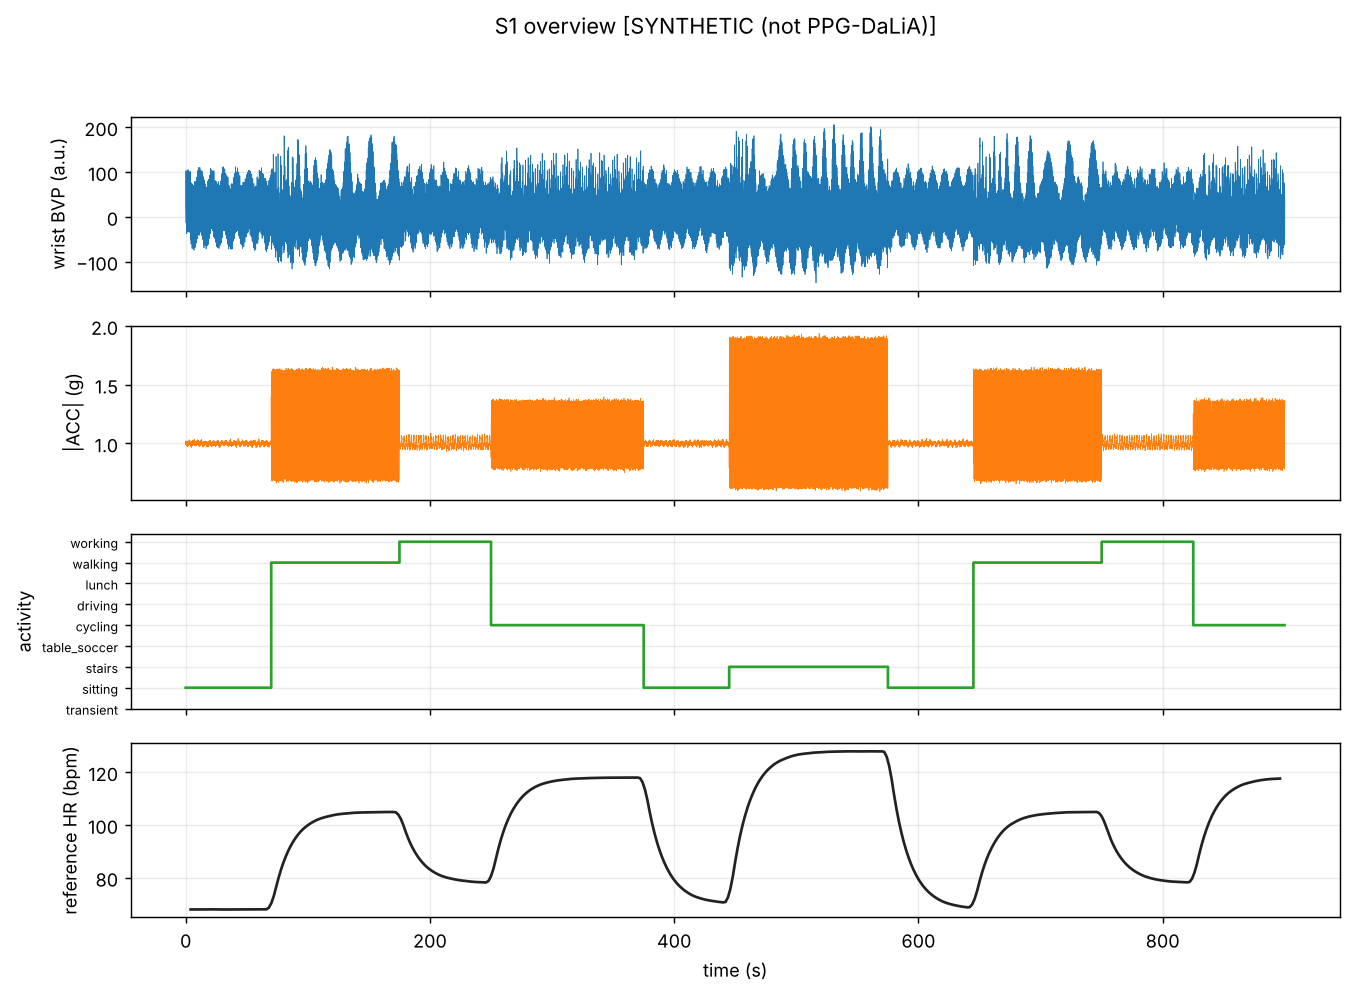

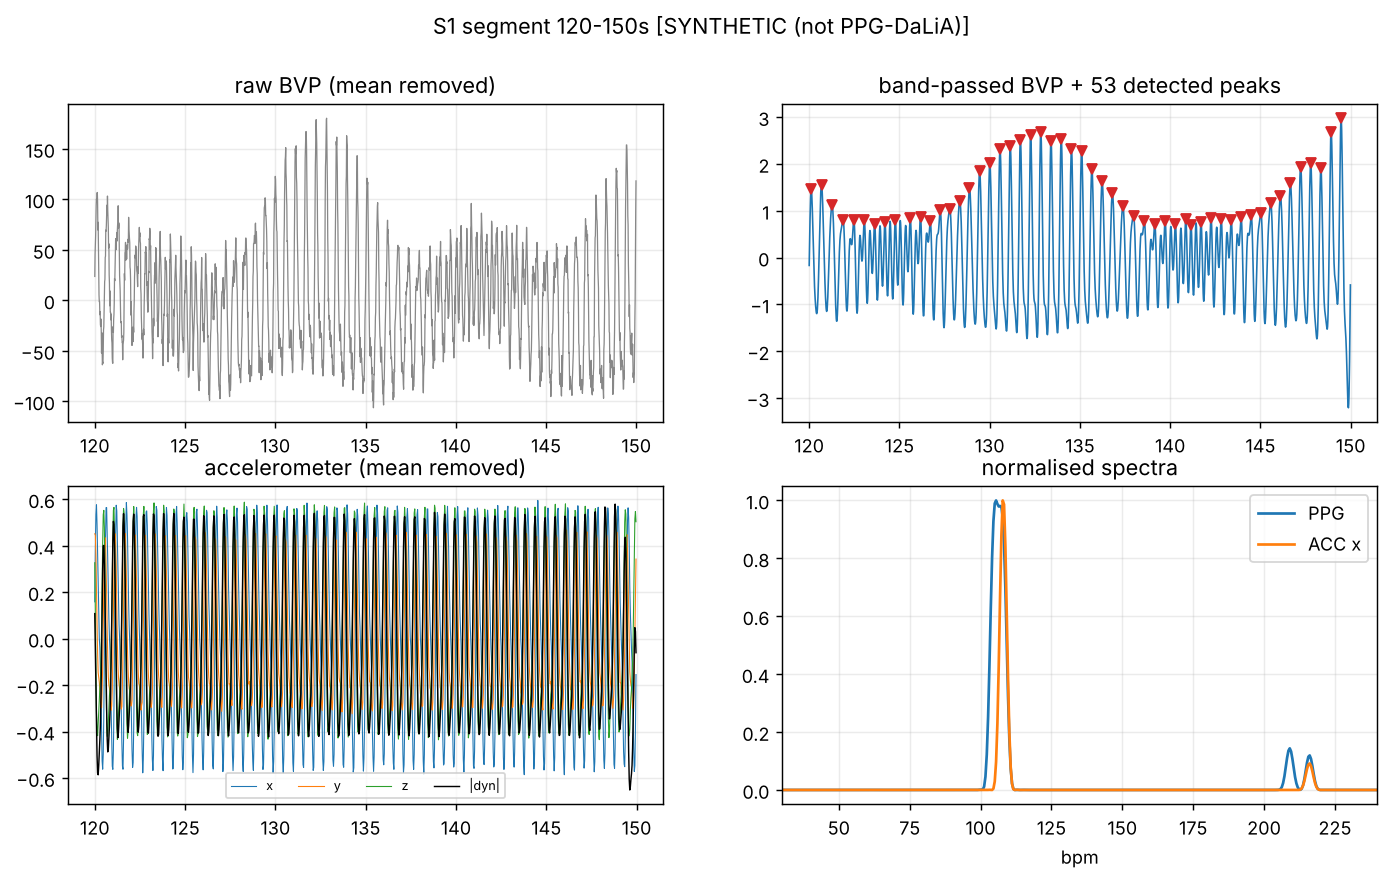

In [5]:
from passos_wearable.visualization import plots as P
P.plot_overview(rec, OUT / "overview.png")
from IPython.display import Image, display
display(Image(str(OUT / "overview.png")))
P.plot_segment(rec, 120, 30, cfg, OUT / "segment_120_30.png"); display(Image(str(OUT / "segment_120_30.png")))

## 7. PPG preprocessing
Band-pass 0.5-4 Hz (4th-order Butterworth, zero-phase) removes baseline wander and high-frequency noise.

In [6]:
from passos_wearable.preprocessing.filters import preprocess_ppg
seg = s.segment(120, 8)
filt = preprocess_ppg(seg.bvp, seg.fs_bvp, cfg)
t = np.arange(len(filt)) / seg.fs_bvp
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(t, seg.bvp, lw=.8); ax[0].set_title(f"raw [{TAG}]"); ax[1].plot(t, filt, lw=.8, color="C1"); ax[1].set_title("band-passed + standardised")
plt.tight_layout(); plt.show()

## 8. HR estimation (peaks -> IBI -> HR)

In [7]:
from passos_wearable.estimation.heart_rate import estimate_hr
w = s.segment(120, 8)
est = estimate_hr(w.bvp, w.fs_bvp, w.acc, w.fs_acc, "peaks", cfg)
print(f"[{TAG}] peaks method, window 120-128 s: {est.hr_bpm:.1f} bpm | {est.n_peaks} peaks, {est.n_valid_ibi} valid IBIs after plausibility filter")
print("IBI (ms):", est.ibi_ms, "| warnings:", est.warnings)

[SYNTHETIC (not PPG-DaLiA)] peaks method, window 120-128 s: 104.8 bpm | 14 peaks, 12 valid IBIs after plausibility filter
IBI (ms): [567.4, 585.2, 607.2, 600.3, 579.7, 571.7, 573.0, 573.2, 564.9, 538.4, 556.9, 553.7] | warnings: ['peak-based and spectral HR disagree by 5.5 bpm']


## 9. Alternative estimation approach
Spectral peak, motion-suppressed spectral peak (excludes ACC-derived movement frequencies and harmonics), and a fusion rule.

In [8]:
est = estimate_hr(w.bvp, w.fs_bvp, w.acc, w.fs_acc, "fusion", cfg)
print(f"[{TAG}] candidates on the same window:", est.candidates, "| chosen:", est.hr_bpm, "| motion freqs (Hz):", est.motion_freqs_hz)

[SYNTHETIC (not PPG-DaLiA)] candidates on the same window: {'peaks': 104.8280131569703, 'spectral': 99.375, 'spectral_motion': 99.375, 'fusion': 99.375} | chosen: 99.375 | motion freqs (Hz): [1.796875]


## 10. Signal-quality analysis

In [9]:
from passos_wearable.evaluation import experiments as X
import time; t0 = time.time()
df = X.run_estimation(rec, cfg)                 # estimation stage: signals only
print(f"{len(df)} windows estimated in {time.time()-t0:.0f}s [{TAG}]")
print(df["sqi_label"].value_counts().to_string())
print(df.groupby("sqi_label")["sqi"].describe())

447 windows estimated in 2s [SYNTHETIC (not PPG-DaLiA)]
sqi_label
high      347
medium     99
low         1
           count  mean  std  min  25%  50%  75%  max
sqi_label                                           
high      347.00  0.86 0.13 0.60 0.78 0.89 0.98 0.99
low         1.00  0.33  NaN 0.33 0.33 0.33 0.33 0.33
medium     99.00  0.55 0.03 0.45 0.52 0.55 0.58 0.60


## 11. Motion analysis

In [10]:
print(df["motion_label"].value_counts().to_string())
print(df[["motion_g", "sqi"]].corr(method="spearman").round(2))

motion_label
high      268
low       162
medium     17
          motion_g   sqi
motion_g      1.00 -0.85
sqi          -0.85  1.00


## 12. Reference-based evaluation
Reference (dataset labels and ECG R-peak HR) is attached **after** estimation. Estimates are not modified in this step.

[SYNTHETIC (not PPG-DaLiA)] vs dataset labels


,n_windows,n_valid,coverage,mae,rmse,bias,medae,std_error,pearson_r,within_tol
method,,,,,,,,,,
peaks,447,447,1.00,3.26,7.65,1.65,0.92,7.48,0.92,0.82
spectral,447,447,1.00,2.64,6.28,0.94,0.23,6.21,0.95,0.85
spectral_motion,447,447,1.00,10.41,23.43,0.04,0.22,23.45,0.54,0.72
fusion,447,447,1.00,9.77,22.35,-0.62,0.20,22.36,0.57,0.73
fusion_continuity,447,447,1.00,6.50,12.71,-2.75,0.20,12.42,0.78,0.73


[SYNTHETIC (not PPG-DaLiA)] vs ECG R-peak HR


,n_windows,n_valid,coverage,mae,rmse,bias,medae,std_error,pearson_r,within_tol
method,,,,,,,,,,
peaks,447,447,1.00,3.23,7.57,1.58,0.94,7.41,0.92,0.82
spectral,447,447,1.00,2.61,6.17,0.88,0.26,6.12,0.95,0.85
spectral_motion,447,447,1.00,10.43,23.44,-0.02,0.26,23.47,0.54,0.72
fusion,447,447,1.00,9.78,22.34,-0.68,0.23,22.35,0.57,0.73
fusion_continuity,447,447,1.00,6.53,12.74,-2.81,0.26,12.44,0.78,0.72


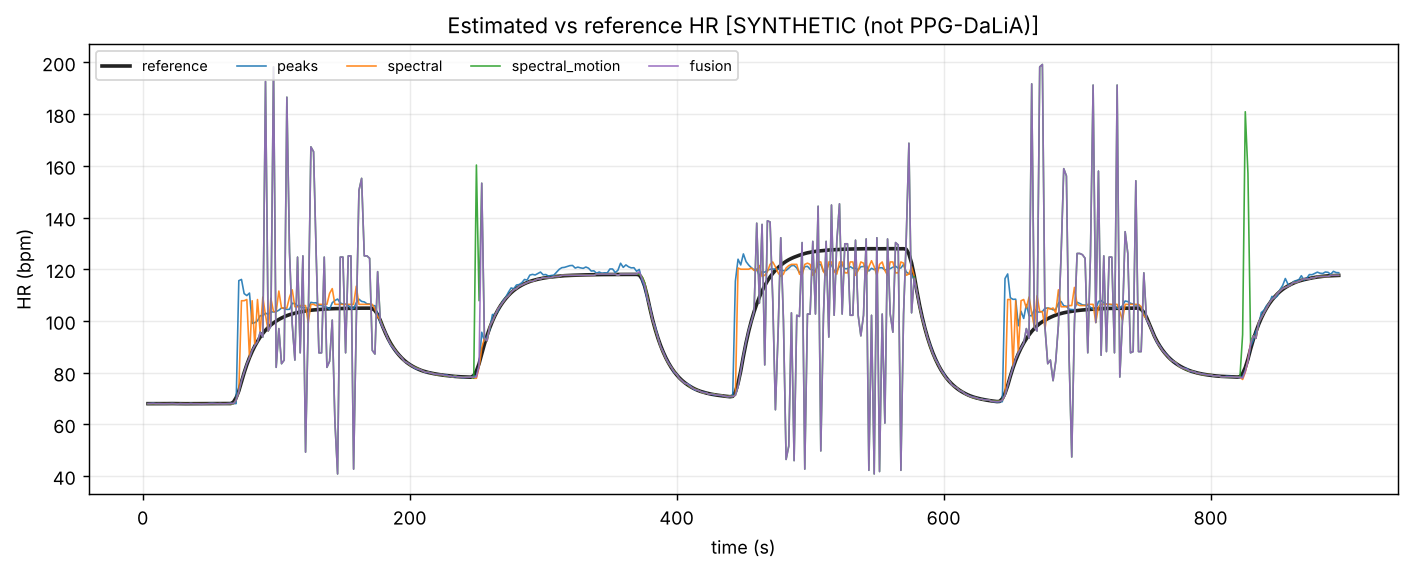

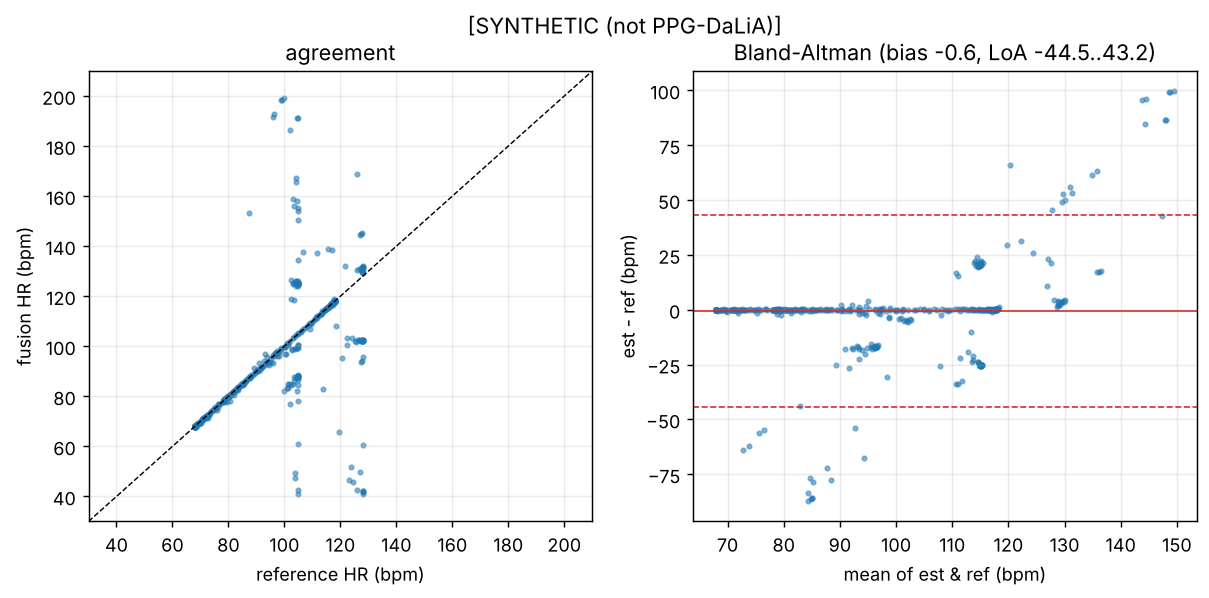

In [11]:
dfe = X.attach_reference(df, rec, cfg)
assert dfe["hr_fusion"].equals(df["hr_fusion"])        # attaching the reference changes no estimate
tol = cfg["evaluation"]["within_tolerance_bpm"]
print(f"[{TAG}] vs dataset labels"); overall = X.summarize(dfe, tol=tol); display(overall)
print(f"[{TAG}] vs ECG R-peak HR"); display(X.summarize(dfe, ref_col="ref_ecg_hr", tol=tol))
P.plot_hr_comparison(dfe, rec, ("peaks","spectral","spectral_motion","fusion"), out_path=OUT/"hr_comparison.png"); display(Image(str(OUT/"hr_comparison.png")))
P.plot_scatter_bland(dfe, rec, "fusion", out_path=OUT/"scatter.png"); display(Image(str(OUT/"scatter.png")))

## 13. Experimental comparison

method,fusion,fusion_continuity,peaks,spectral,spectral_motion
activity,,,,,
cycling,0.98,0.36,1.55,0.34,3.70
sitting,0.33,0.46,0.66,0.17,0.34
stairs,26.41,20.39,9.04,8.80,26.41
walking,23.75,13.02,6.02,5.17,23.75
working,0.37,1.74,0.18,0.19,0.57


method,fusion,fusion_continuity,peaks,spectral,spectral_motion
motion_label,,,,,
high,16.19,10.30,5.29,4.28,16.19
low,0.10,0.54,0.15,0.12,0.12
medium,0.78,3.39,0.86,0.84,17.38


SQI/confidence gating (fusion): accuracy vs coverage


,filter,n_windows,n_valid,coverage,mae,rmse,bias,medae,std_error,pearson_r,within_tol,kept_fraction
0,all windows,447,447,1.00,9.77,22.35,-0.62,0.20,22.36,0.57,0.73,1.00
1,confidence >= medium,447,416,0.93,10.17,22.91,-0.67,0.19,22.92,0.57,0.72,0.93
2,confidence == high,447,179,0.40,0.17,0.33,-0.09,0.09,0.32,1.00,1.00,0.40


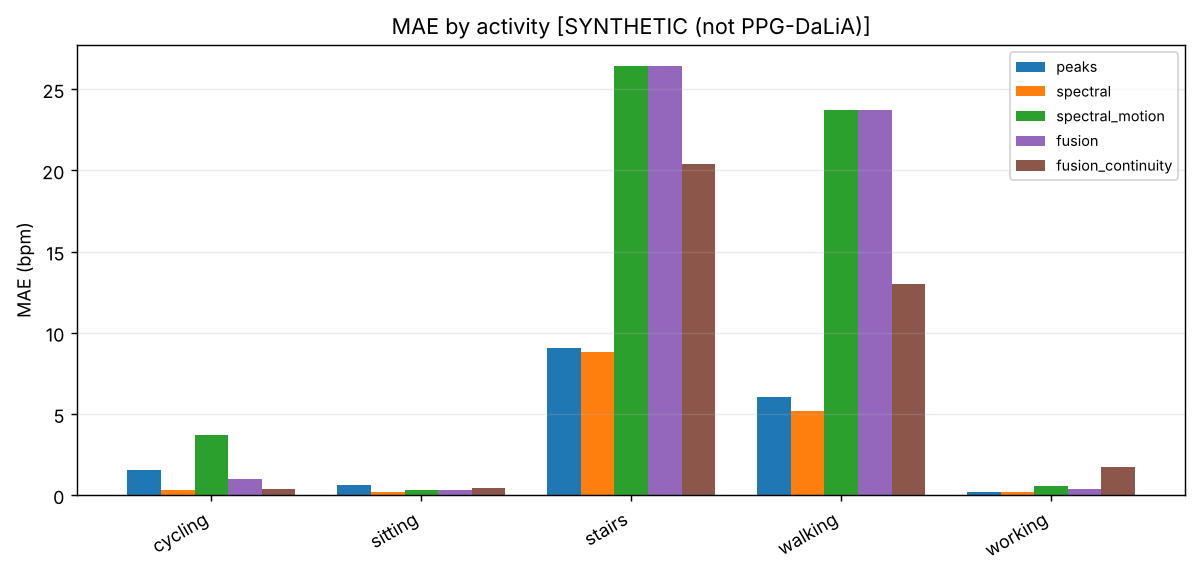

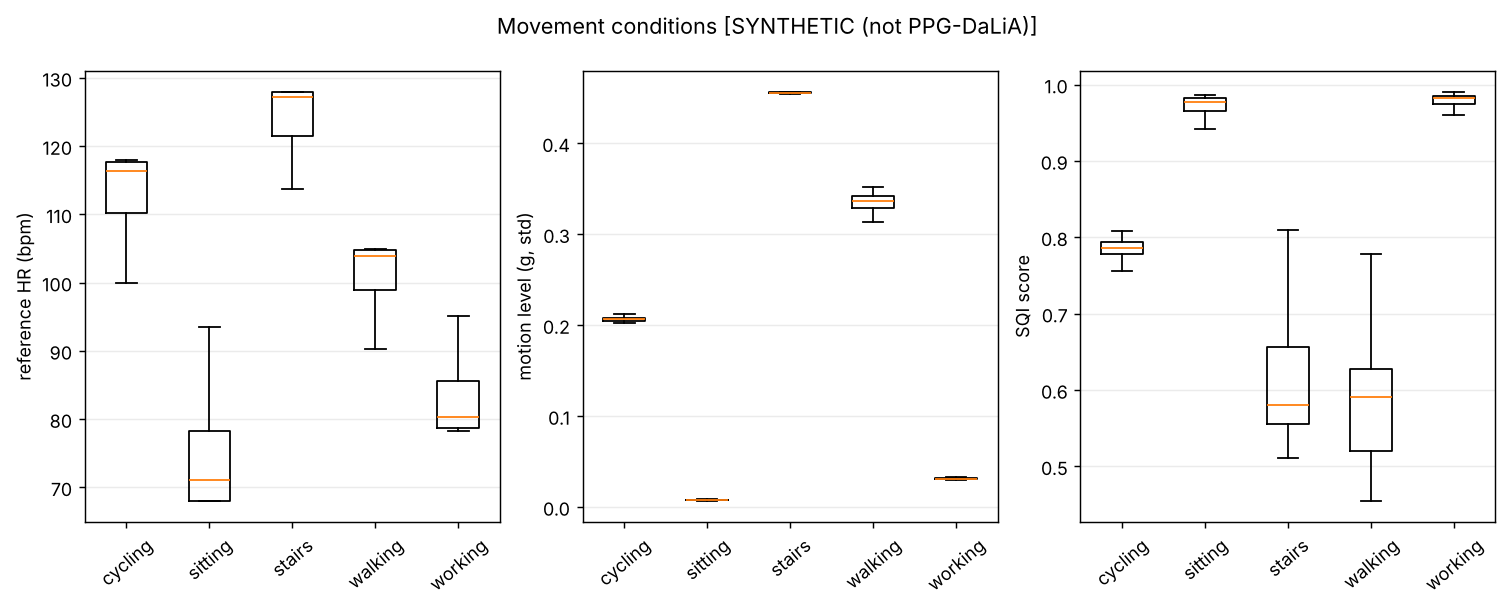

In [12]:
by_act = X.summarize_by(dfe, "activity", tol=tol); display(by_act.pivot(index="activity", columns="method", values="mae").round(2))
by_mot = X.summarize_by(dfe, "motion_label", tol=tol); display(by_mot.pivot(index="motion_label", columns="method", values="mae").round(2))
print("SQI/confidence gating (fusion): accuracy vs coverage"); display(X.sqi_gating(dfe, tol=tol))
P.plot_error_by_activity(by_act, rec, out_path=OUT/"error_by_activity.png"); display(Image(str(OUT/"error_by_activity.png")))
P.plot_activity_comparison(dfe, rec, out_path=OUT/"activity_comparison.png"); display(Image(str(OUT/"activity_comparison.png")))

## 14. Error analysis and failure cases

Ten worst windows for fusion:


,start_s,activity,hr_fusion,ref_label_hr,abs_error,sqi,motion_g,confidence
335,670.00,walking,199.22,99.70,99.52,0.51,0.35,medium
334,668.00,walking,198.28,98.96,99.32,0.48,0.35,medium
47,94.00,walking,198.28,99.23,99.05,0.50,0.33,medium
44,88.00,walking,192.66,96.39,96.26,0.46,0.34,medium
331,662.00,walking,191.72,95.93,95.79,0.45,0.33,medium
272,544.00,stairs,40.78,127.93,87.15,0.54,0.46,medium
354,708.00,walking,191.25,104.54,86.71,0.51,0.35,medium
363,726.00,walking,191.25,104.87,86.38,0.50,0.33,medium
274,548.00,stairs,41.72,127.91,86.19,0.54,0.45,medium
270,540.00,stairs,42.19,127.94,85.76,0.54,0.46,medium


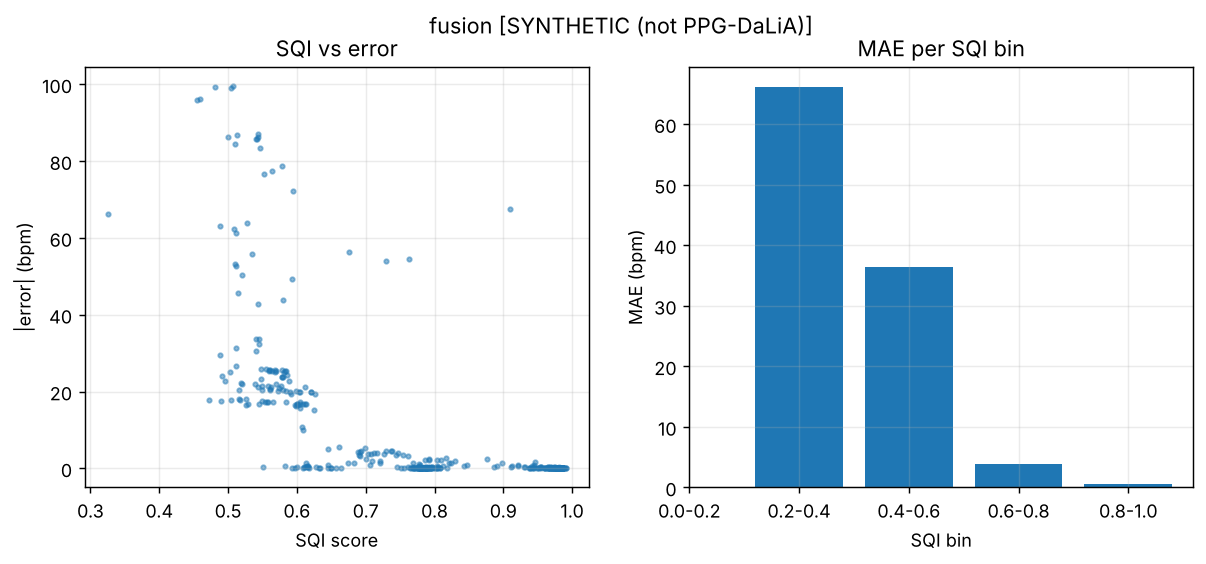

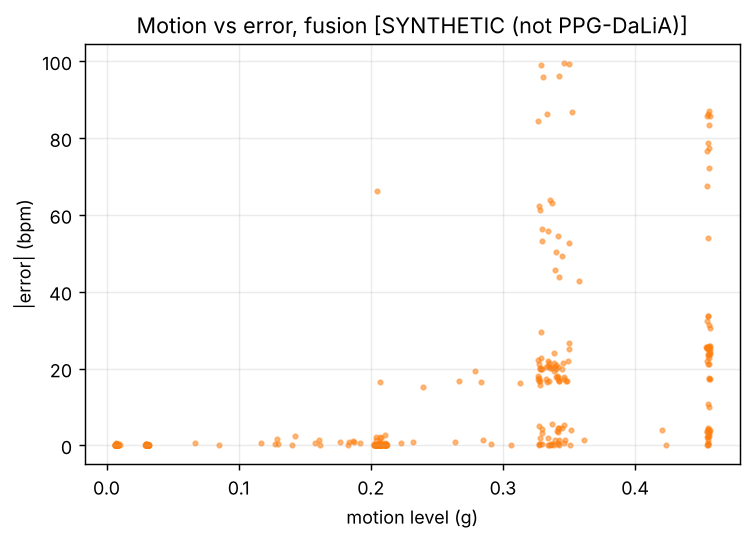

39

In [13]:
print("Ten worst windows for fusion:"); display(X.worst_windows(dfe, "fusion"))
P.plot_sqi_vs_error(dfe, rec, "fusion", out_path=OUT/"sqi_vs_error.png"); display(Image(str(OUT/"sqi_vs_error.png")))
P.plot_motion_vs_error(dfe, rec, "fusion", out_path=OUT/"motion_vs_error.png"); display(Image(str(OUT/"motion_vs_error.png")))
dfe.to_csv(OUT / "window_estimates.csv", index=False); overall.to_csv(OUT / "metrics_overall.csv")
(OUT / "SOURCE.txt").write_text(f"data source: {TAG}\n")

## 15. AI analysis tool demonstration

In [14]:
from passos_wearable.tools.analysis_tool import analyze_hr_segment, TOOL_SCHEMA
from passos_wearable.agent.prompts import explain_result
res = analyze_hr_segment("S1", 120, 30, "fusion", True, config=cfg, recording=rec)
print(json.dumps(res, indent=2)); print("\n" + explain_result(res))
print("\nInvalid request ->", analyze_hr_segment("S1", -3, 30, config=cfg, recording=rec)["error_message"])

{
  "status": "ok",
  "request": {
    "subject": "S1",
    "start_s": 120,
    "duration_s": 30,
    "method": "fusion",
    "include_reference": true
  },
  "data_source": "SYNTHETIC (not PPG-DaLiA)",
  "is_synthetic": true,
  "segment": {
    "start_s": 120.0,
    "end_s": 150.0,
    "duration_s": 30.0,
    "n_windows": 12,
    "window_s": 8.0,
    "step_s": 2.0
  },
  "estimate": {
    "method": "fusion",
    "hr_bpm": 93.52,
    "window_to_window_std_bpm": 36.42,
    "window_hr_min_bpm": 40.78,
    "window_hr_max_bpm": 167.34,
    "confidence": "low"
  },
  "alternatives_bpm": {
    "peaks": 106.52,
    "spectral": 106.41,
    "spectral_motion": 93.52,
    "fusion": 93.52
  },
  "signal_quality": {
    "mean_sqi": 0.58,
    "label": "medium",
    "fraction_low_quality_windows": 0.0,
    "flag_counts": {
      "low_spectral_concentration": 10
    }
  },
  "motion": {
    "mean_level_g": 0.34,
    "label": "high",
    "fraction_high_motion_windows": 1.0
  },
  "plausibility": {
    

## 16. AI agent demonstration
Backend `rule` (deterministic, offline) unless `ANTHROPIC_API_KEY` and the `anthropic` package are present, in which case `auto` selects real LLM function calling. The notebook reports which backend ran.

In [15]:
from passos_wearable.agent.agent import HRAgent
agent = HRAgent(cfg, backend="auto", recording=rec)
print("backend used:", agent.backend)
for q in ["analyse S1 from 120 s for 30 s with fusion", "why this confidence?", "how does it compare to the reference?", "do I have an arrhythmia?"]:
    print("\n>>> " + q); print(agent.ask(q).text)

backend used: rule

>>> analyse S1 from 120 s for 30 s with fusion
** SYNTHETIC DATA - generated test signal, NOT PPG-DaLiA. Figures below do not describe real performance. **
Segment 120-150 s of S1 (12 windows of 8 s, step 2 s), data source: SYNTHETIC (not PPG-DaLiA).
Estimated HR: 93.5 bpm (method 'fusion', median over windows; window-to-window SD 36.4 bpm, range 40.8-167.3 bpm).
Confidence: low.
Other methods on the same segment: peaks 106.5 bpm, spectral 106.4 bpm, spectral_motion 93.5 bpm.
Signal quality: medium (mean SQI 0.58; 0% of windows low quality).
Movement: high (mean dynamic-acceleration SD 0.34 g; 100% of windows high-motion).
Annotated activity in this segment (context only, not used by the estimator): walking 100%.
Mean disagreement between peak-based and spectral estimates: 2.1 bpm.
Warnings: peak-based and spectral HR disagree by N bpm (x3).
Reference comparison (evaluation only, not used for the estimate): dataset label HR 104.49 bpm, ECG R-peak HR 104.48 bpm. Abso

## 17. Conclusions and limitations

In [16]:
print(f"Run mode: {TAG}")
best = overall["mae"].idxmin()
print(f"Lowest MAE vs dataset labels in this run: {best} ({overall.loc[best,'mae']:.2f} bpm) [{TAG}]")
if not REAL:
    print("\nThis run used SYNTHETIC data because PPG-DaLiA was not available. The numbers above only show that the pipeline executes; they are not evidence about real-world accuracy.")

Run mode: SYNTHETIC (not PPG-DaLiA)
Lowest MAE vs dataset labels in this run: spectral (2.64 bpm) [SYNTHETIC (not PPG-DaLiA)]

This run used SYNTHETIC data because PPG-DaLiA was not available. The numbers above only show that the pipeline executes; they are not evidence about real-world accuracy.


**Limitations.** Heuristic SQI / motion thresholds (not tuned on PPG-DaLiA); only S1 (no generalisation claim); 8 s windows smooth fast HR changes;
hard motion-frequency suppression fails when HR coincides with movement cadence; reference labels are themselves ECG-derived estimates;
not a medical device. See `reports/limitations.md`.